# LLM Lab — Extra experiment: last 8 layers, up to 5 epochs


This runs **only one experiment**: fine-tune the last 8 RoBERTa encoder blocks and the classification head for at most 5 epochs, with early stopping. The original 3-epoch results are left untouched. Outputs are saved after each epoch and at the end.


## 1 — Setup

For a fair comparison with the previous experiment, we keep the same dataset, model, seed, learning rate, optimizer, batch sizes and evaluation. Only the maximum number of epochs changes from 3 to 5.

In [1]:
import os, gc, json, time, random
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
    DataCollatorWithPadding, pipeline
)
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, roc_curve, matthews_corrcoef
)

SEED = 42
MODEL_NAME = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MAX_LENGTH = 128
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
EPOCHS = 5
EARLY_STOP_PATIENCE = 2
CLASS_NAMES = ['negative', 'positive']

RESULTS_DIR = Path('/kaggle/working/llm_last8_5epochs') if Path('/kaggle/working').exists() else Path('llm_last8_5epochs')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
(RESULTS_DIR / 'checkpoints').mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Device:', DEVICE, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'not available')
print('torch:', torch.__version__)
print('Output folder:', RESULTS_DIR)
print('Each result will be saved immediately after completion.')
print(f'Settings: maximum epochs={EPOCHS}, batch size={TRAIN_BATCH_SIZE}, eval batch size={EVAL_BATCH_SIZE}, seed={SEED}')


Device: cuda | GPU: Tesla T4
torch: 2.11.0+cu130
Output folder: /kaggle/working/llm_last8_5epochs
Each result will be saved immediately after completion.
Settings: maximum epochs=5, batch size=16, eval batch size=32, seed=42


## 2 — Load Rotten Tomatoes and the tokenizer

In [2]:
dataset = load_dataset('cornell-movie-review-data/rotten_tomatoes')
print(dataset)
print('First training example:', dataset['train'][0])
print('Label names:', dataset['train'].features['label'].names)

for split in ['train', 'validation', 'test']:
    counts = pd.Series(list(dataset[split]['label'])).value_counts().sort_index()
    print(f'{split}: {len(dataset[split]):,} examples | negative={counts.get(0, 0):,} | positive={counts.get(1, 0):,}')

assert dataset['train'].features['label'].names in (
    ['neg', 'pos'],
    ['negative', 'positive']
), "Unexpected label ordering"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
test_texts = list(dataset['test']['text'])
y_test = np.asarray(list(dataset['test']['label']), dtype=int)
assert len(test_texts) == len(y_test) and all(isinstance(x, str) for x in test_texts)
print('Tokenizer ready. Test data:', len(test_texts))

README.md:   0%|          | 0.00/7.46k [00:00<?, ?B/s]

train.parquet: reconstructing file:   0%|          |  0.00B /  699kB            

train.parquet: downloading bytes:           |  0.00B            

validation.parquet: reconstructing file:   0%|          |  0.00B / 90.0kB            

validation.parquet: downloading bytes:           |  0.00B            

test.parquet: reconstructing file:   0%|          |  0.00B / 92.2kB            

... (6 outputs left out)

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Tokenizer ready. Test data: 1066


## 3 — Tokenization and data loaders

In [3]:
def tokenize_rows(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH)

tok_data = dataset.map(tokenize_rows, batched=True, desc='Tokenizing movie reviews')
tok_data = tok_data.remove_columns('text').rename_column('label', 'labels')
tok_data.set_format(type='torch', columns=['input_ids', 'attention_mask', 'labels'])
collator = DataCollatorWithPadding(tokenizer=tokenizer)

def fresh_train_loader():
    # Same seed in every experiment = repeatable shuffling.
    gen = torch.Generator().manual_seed(SEED)
    return DataLoader(tok_data['train'], batch_size=TRAIN_BATCH_SIZE,
                      shuffle=True, collate_fn=collator, generator=gen)

validation_loader = DataLoader(tok_data['validation'], batch_size=EVAL_BATCH_SIZE,
                               shuffle=False, collate_fn=collator)
test_loader = DataLoader(tok_data['test'], batch_size=EVAL_BATCH_SIZE,
                         shuffle=False, collate_fn=collator)
print('Data loaders ready | validation batches:', len(validation_loader),
      '| test batches:', len(test_loader))


Tokenizing movie reviews:   0%|          | 0/8530 [00:00<?, ? examples/s]

Tokenizing movie reviews:   0%|          | 0/1066 [00:00<?, ? examples/s]

Tokenizing movie reviews:   0%|          | 0/1066 [00:00<?, ? examples/s]

Data loaders ready | validation batches: 34 | test batches: 34


## 4 — Test metrics and saving functions

Accuracy, precision, recall, macro F1, weighted F1, ROC-AUC, MCC, class reports, confusion matrix and predictions are calculated **on the same untouched test split**. Test metrics are calculated only after selecting the best validation checkpoint.

In [4]:
def slugify(s):
    return ''.join(c if c.isalnum() else '_' for c in s.lower()).strip('_')


def save_evaluation(name, y_true, probabilities_positive, elapsed_seconds, extra=None):
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(probabilities_positive, dtype=float)
    assert y_true.shape == prob.shape and np.isfinite(prob).all()
    assert ((prob >= 0) & (prob <= 1)).all(), 'Expected scores in [0, 1]'
    pred = (prob >= 0.5).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(
        y_true, pred, labels=[0, 1], average='macro', zero_division=0)
    pr_w, rc_w, f1_w, _ = precision_recall_fscore_support(
        y_true, pred, labels=[0, 1], average='weighted', zero_division=0)
    report = classification_report(y_true, pred, labels=[0, 1],
                                   target_names=CLASS_NAMES, zero_division=0,
                                   output_dict=True)
    roc_auc = float(roc_auc_score(y_true, prob)) if len(np.unique(y_true)) == 2 else float('nan')
    result = {
        'experiment': name,
        'accuracy': float(accuracy_score(y_true, pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, pred)),
        'precision_macro': float(pr), 'recall_macro': float(rc), 'f1_macro': float(f1),
        'precision_weighted': float(pr_w), 'recall_weighted': float(rc_w), 'f1_weighted': float(f1_w),
        'roc_auc': roc_auc, 'mcc': float(matthews_corrcoef(y_true, pred)),
        'time_seconds': round(float(elapsed_seconds), 1),
        'test_samples': int(len(y_true))
    }
    if extra:
        result.update(extra)
    slug = slugify(name)

    # Save results after EACH experiment (not only after the final comparison cell).
    with open(RESULTS_DIR / f'{slug}_metrics.json', 'w') as f:
        json.dump(result, f, indent=2)
    pd.DataFrame(report).transpose().to_csv(RESULTS_DIR / f'{slug}_class_report.csv')
    pred_df = pd.DataFrame({
        'review': test_texts, 'true_label': y_true, 'predicted_label': pred,
        'positive_score': prob, 'predicted_class_confidence': np.maximum(prob, 1 - prob),
        'correct': (pred == y_true)
    })
    pred_df.to_csv(RESULTS_DIR / f'{slug}_predictions.csv', index=False)

    print('\n' + '=' * 72)
    print(name)
    print(classification_report(y_true, pred, target_names=CLASS_NAMES, zero_division=0))
    print(f'Accuracy: {result["accuracy"]:.4f} | Macro F1: {result["f1_macro"]:.4f} '
          f'| ROC-AUC: {roc_auc:.4f} | Time: {elapsed_seconds:.1f}s')

    fig, ax = plt.subplots(figsize=(4.7, 4.0))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred, labels=[0, 1]),
                           display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(name + ' — confusion matrix')
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / f'{slug}_confusion.png', dpi=150)
    plt.show()

    if np.isfinite(roc_auc):
        fpr, tpr, _ = roc_curve(y_true, prob)
        fig, ax = plt.subplots(figsize=(4.7, 4.0))
        ax.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
        ax.plot([0, 1], [0, 1], '--', alpha=0.5, label='Random baseline')
        ax.set(xlabel='False positive rate', ylabel='True positive rate', title=name + ' — ROC')
        ax.legend(loc='lower right')
        fig.tight_layout()
        fig.savefig(RESULTS_DIR / f'{slug}_roc.png', dpi=150)
        plt.show()
    print('Saved metrics, classification report, predictions, confusion matrix and ROC plot.')
    return result


def load_saved_results():
    rows = []
    for file in sorted(RESULTS_DIR.glob('*_metrics.json')):
        with open(file) as f:
            rows.append(json.load(f))
    if not rows:
        print('No saved results yet. Run at least one experiment first.')
        return pd.DataFrame()
    df = pd.DataFrame(rows).drop_duplicates('experiment', keep='last')
    order = ['Part 1 - Zero-shot', 'Part 2 - Strict linear probe',
             'Part 3A - Full fine-tuning', 'Part 3B - Last 4 layers',
             'Optional - Head-only fine-tuning', 'Optional - Last 8 layers']
    df['__order'] = df['experiment'].map({s: i for i, s in enumerate(order)}).fillna(999)
    return df.sort_values('__order').drop(columns='__order').reset_index(drop=True)

print('Evaluation and incremental saving ready.')

Evaluation and incremental saving ready.


## 5 — Model architecture

RoBERTa has 12 encoder blocks. Blocks 0–3 and embeddings are frozen; blocks 4–11 and the two-class classification head are trainable. This exactly matches the previous *last 8 layers* setting.

In [5]:
class StrictLinearProbe(nn.Module):
    """Frozen RoBERTa backbone + a genuinely single linear output layer."""
    def __init__(self, pretrained_name):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(pretrained_name)
        self.encoder.requires_grad_(False)
        self.classifier = nn.Linear(self.encoder.config.hidden_size, 2)

    def forward(self, input_ids, attention_mask, labels=None):
        self.encoder.eval()  # no dropout in frozen features
        with torch.no_grad():
            cls_features = self.encoder(input_ids=input_ids,
                                        attention_mask=attention_mask).last_hidden_state[:, 0, :]
        logits = self.classifier(cls_features)
        loss = F.cross_entropy(logits, labels) if labels is not None else None
        return SimpleNamespace(loss=loss, logits=logits)


def create_model(mode):
    if mode == 'strict_linear':
        model = StrictLinearProbe(MODEL_NAME)
    else:
        model = AutoModelForSequenceClassification.from_pretrained(
            MODEL_NAME, num_labels=2, ignore_mismatched_sizes=True,
            id2label={0: 'negative', 1: 'positive'},
            label2id={'negative': 0, 'positive': 1}
        )
        if mode in ('head_only', 'last_4', 'last_8'):
            model.roberta.requires_grad_(False)
            if mode in ('last_4', 'last_8'):
                count = 4 if mode == 'last_4' else 8
                for layer in model.roberta.encoder.layer[-count:]:
                    layer.requires_grad_(True)
        elif mode != 'full':
            raise ValueError('Unknown experiment mode: ' + mode)
    model = model.to(DEVICE)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print(f'{mode}: {trainable:,} / {total:,} trainable parameters ({100*trainable/total:.2f}%)')
    return model, trainable, total


def set_training_modes(model, mode):
    model.train()
    if mode == 'strict_linear':
        model.encoder.eval()
    elif mode == 'head_only':
        model.roberta.eval()
    elif mode in ('last_4', 'last_8'):
        # Keep frozen layers deterministic (avoid dropout changes in frozen features).
        model.roberta.embeddings.eval()
        n_frozen = 12 - (4 if mode == 'last_4' else 8)
        for layer in model.roberta.encoder.layer[:n_frozen]:
            layer.eval()

print('Model configurations are ready.')

Model configurations are ready.


## 6 — Validation function

In [6]:
def evaluate_model(model, data_loader):
    model.eval()
    y_true, probabilities = [], []
    loss_sum, count = 0.0, 0
    with torch.inference_mode():
        for batch in data_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast('cuda', enabled=DEVICE.type == 'cuda'):
                output = model(**batch)
            p_positive = torch.softmax(output.logits.float(), dim=-1)[:, 1]
            y_true.extend(batch['labels'].cpu().tolist())
            probabilities.extend(p_positive.cpu().tolist())
            batch_size = len(batch['labels'])
            loss_sum += output.loss.item() * batch_size
            count += batch_size
    return np.asarray(y_true, dtype=int), np.asarray(probabilities, dtype=float), loss_sum / count

print('Prediction and validation function ready.')

Prediction and validation function ready.


## 7 — Training loop



In [7]:
def train_experiment(name, mode, learning_rate, epochs=EPOCHS):
    print('\n' + '=' * 75)
    print('STARTING:', name, '| mode:', mode, '| epochs:', epochs)
    print('=' * 75, flush=True)
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    torch.manual_seed(SEED)
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)

    total_start = time.perf_counter()
    model, n_trainable, n_total = create_model(mode)
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad),
                                  lr=learning_rate, weight_decay=0.01)
    amp_enabled = DEVICE.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    train_loader = fresh_train_loader()
    best_validation_f1 = -1.0
    best_epoch = 0
    stagnant_epochs = 0
    history = []
    ckpt = RESULTS_DIR / 'checkpoints' / f'{slugify(name)}_best.pt'
    training_start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        set_training_modes(model, mode)
        epoch_total_loss, seen = 0.0, 0
        progress = tqdm(train_loader, desc=f'{mode}: epoch {epoch}/{epochs}', unit='batch', leave=True)
        for batch in progress:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda', enabled=amp_enabled):
                output = model(**batch)
                loss = output.loss
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_((p for p in model.parameters() if p.requires_grad), 1.0)
            scaler.step(optimizer)
            scaler.update()
            batch_size = len(batch['labels'])
            epoch_total_loss += float(loss.detach()) * batch_size
            seen += batch_size
            progress.set_postfix(loss=f'{epoch_total_loss / seen:.4f}')

        val_true, val_prob, val_loss = evaluate_model(model, validation_loader)
        val_pred = (val_prob >= 0.5).astype(int)
        val_acc = float(accuracy_score(val_true, val_pred))
        val_f1 = float(precision_recall_fscore_support(
            val_true, val_pred, average='macro', zero_division=0)[2])
        epoch_row = {'experiment': name, 'epoch': epoch,
                     'train_loss': epoch_total_loss / seen, 'val_loss': float(val_loss),
                     'val_accuracy': val_acc, 'val_f1_macro': val_f1}
        history.append(epoch_row)
        pd.DataFrame(history).to_csv(RESULTS_DIR / f'{slugify(name)}_history.csv', index=False)
        print(f'Epoch {epoch}/{epochs}: train loss={epoch_row["train_loss"]:.4f}, '
              f'val loss={val_loss:.4f}, val accuracy={val_acc:.4f}, '
              f'val macro F1={val_f1:.4f}', flush=True)
        if val_f1 > best_validation_f1 + 1e-8:
            best_validation_f1 = val_f1
            best_epoch = epoch
            stagnant_epochs = 0
            torch.save(model.state_dict(), ckpt)
            print('Saved better checkpoint:', ckpt, flush=True)
        else:
            stagnant_epochs += 1
            if stagnant_epochs >= EARLY_STOP_PATIENCE:
                print('Early stopping: validation macro F1 did not improve.', flush=True)
                break

    train_seconds = time.perf_counter() - training_start
    print(f'Loading best checkpoint from epoch {best_epoch} and testing...', flush=True)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
    test_true, test_probability, test_loss = evaluate_model(model, test_loader)
    peak_mem_mb = round(torch.cuda.max_memory_allocated() / (1024**2), 1) if amp_enabled else None
    result = save_evaluation(name, test_true, test_probability,
                             time.perf_counter() - total_start,
                             extra={'mode': mode, 'learning_rate': learning_rate,
                                    'epochs_completed': len(history), 'best_epoch': best_epoch,
                                    'best_validation_f1': best_validation_f1,
                                    'train_loss_best_epoch': history[best_epoch - 1]['train_loss'],
                                    'test_loss': float(test_loss),
                                    'trainable_parameters': int(n_trainable),
                                    'total_parameters': int(n_total),
                                    'trainable_percent': round(100 * n_trainable / n_total, 3),
                                    'training_seconds': round(train_seconds, 1),
                                    'peak_cuda_memory_mb': peak_mem_mb})
    print('COMPLETED:', name, '| saved checkpoint and metrics.', flush=True)
    del model, optimizer, scaler
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return result

print('Training loop ready. The next three experiment cells start training.')

Training loop ready. The next three experiment cells start training.


## 8 — Run the 5-epoch experiment

This is the only training cell, It may stop before epoch 5 if validation macro F1 does not improve for two consecutive epochs. It will print results, save plots and select the best checkpoint automatically.


STARTING: Last 8 layers - up to 5 epochs | mode: last_8 | epochs: 5


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `3`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3, 768]) vs model:torch.Size([2, 768])
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([3]) vs model:torch.Size([2])          

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect 

... (9 outputs left out)

last_8: epoch 4/5:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 4/5: train loss=0.0889, val loss=0.7355, val accuracy=0.8790, val macro F1=0.8790


last_8: epoch 5/5:   0%|          | 0/534 [00:00<?, ?batch/s]

Epoch 5/5: train loss=0.0449, val loss=0.7820, val accuracy=0.8790, val macro F1=0.8790
Early stopping: validation macro F1 did not improve.
Loading best checkpoint from epoch 3 and testing...

Last 8 layers - up to 5 epochs
              precision    recall  f1-score   support

    negative       0.82      0.94      0.88       533
    positive       0.93      0.79      0.86       533

    accuracy                           0.87      1066
   macro avg       0.88      0.87      0.87      1066
weighted avg       0.88      0.87      0.87      1066

Accuracy: 0.8668 | Macro F1: 0.8660 | ROC-AUC: 0.9397 | Time: 178.4s


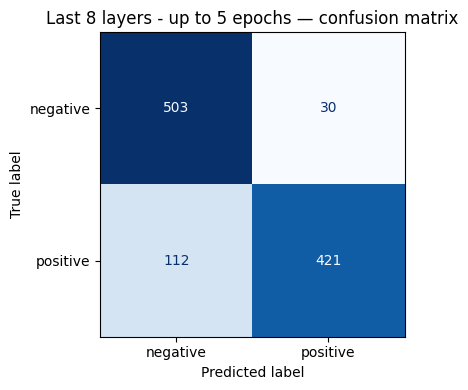

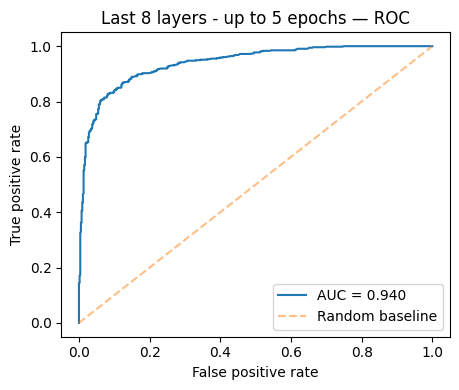

Saved metrics, classification report, predictions, confusion matrix and ROC plot.
COMPLETED: Last 8 layers - up to 5 epochs | saved checkpoint and metrics.
Experiment completed; result files saved in: /kaggle/working/llm_last8_5epochs


In [8]:
last8_5_result = train_experiment(
    'Last 8 layers - up to 5 epochs',
    'last_8',
    learning_rate=3e-5,
    epochs=5
)
print('Experiment completed; result files saved in:', RESULTS_DIR)


## 9 — Validation curves and comparison with the original 3-epoch run

The reference points below were read from the previous already-executed notebook (tp_llm). They are historical values, not results from this new run. In principle, the first 3 epochs should be close with the same seed, although small GPU nondeterminism is possible.

| Epoch | Original validation macro F1 | Original validation loss |
|---|---:|---:|
| 1 | 0.8752 | 0.3065 |
| 2 | 0.8824 | 0.3726 |
| 3 | 0.8834 | 0.4725 |


,epoch,train_loss,val_loss,val_accuracy,val_f1_macro
0,1,0.3597,0.3065,0.8752,0.8752
1,2,0.2319,0.3726,0.8827,0.8824
2,3,0.1506,0.4725,0.8837,0.8834
3,4,0.0889,0.7355,0.8790,0.8790
4,5,0.0449,0.7820,0.8790,0.8790


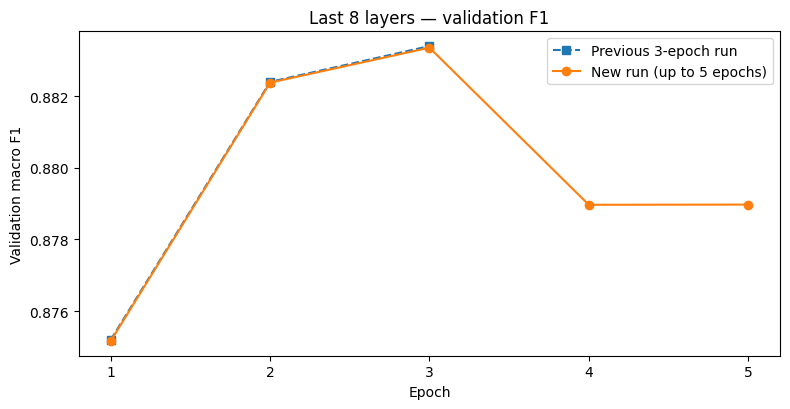

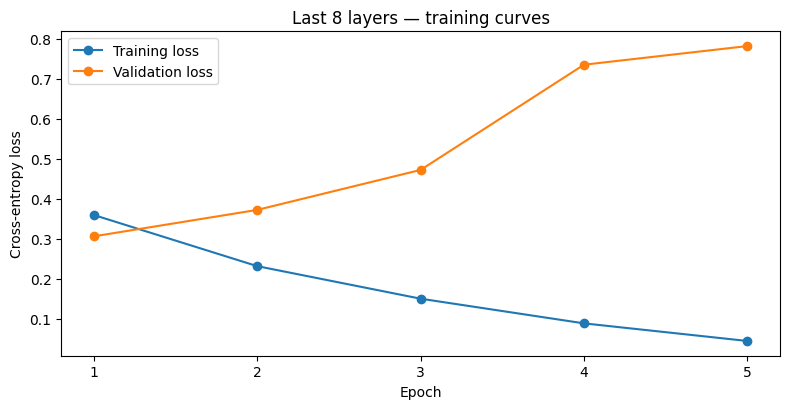

In [9]:
history_path = RESULTS_DIR / f'{slugify("Last 8 layers - up to 5 epochs")}_history.csv'
if history_path.exists():
    history = pd.read_csv(history_path)
    display(history[['epoch', 'train_loss', 'val_loss', 'val_accuracy', 'val_f1_macro']].round(4))
    old_epochs = [1, 2, 3]
    old_f1 = [0.8752, 0.8824, 0.8834]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(old_epochs, old_f1, marker='s', linestyle='--', label='Previous 3-epoch run')
    ax.plot(history['epoch'], history['val_f1_macro'], marker='o', label='New run (up to 5 epochs)')
    ax.set(xlabel='Epoch', ylabel='Validation macro F1', title='Last 8 layers — validation F1')
    ax.set_xticks(range(1, 6))
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / 'last8_validation_f1_vs_previous.png', dpi=160)
    plt.show()
    fig, ax = plt.subplots(figsize=(8, 4.2))
    ax.plot(history['epoch'], history['train_loss'], marker='o', label='Training loss')
    ax.plot(history['epoch'], history['val_loss'], marker='o', label='Validation loss')
    ax.set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Last 8 layers — training curves')
    ax.set_xticks(range(1, 6))
    ax.legend()
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / 'last8_train_validation_losses.png', dpi=160)
    plt.show()
else:
    print('No history file yet — run the training cell first.')


## 10 — Compare final test results


,experiment,accuracy,f1_macro,roc_auc,best_epoch,trainable_percent
0,Last 8 layers — previous 3 epochs,0.8668,0.8660,0.9397,3,45.966
1,Full fine-tuning — previous notebook,0.8687,0.8687,0.9421,1,100.000
2,Last 8 layers - up to 5 epochs,0.8668,0.8660,0.9397,3,45.966


Accuracy change versus previous 3 epochs: -0.00 percentage points
Macro F1 change versus previous 3 epochs: -0.00 percentage points
Best validation epoch: 3 | epochs completed: 5


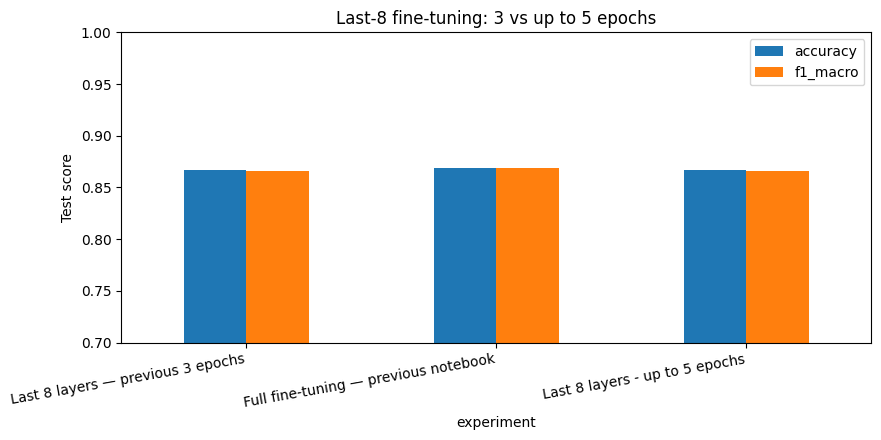

In [10]:
# Verified reference values from the already-executed original notebook.
reference = [
    {'experiment': 'Last 8 layers — previous 3 epochs', 'accuracy': 0.8668,
     'f1_macro': 0.8660, 'roc_auc': 0.9397, 'best_epoch': 3,
     'trainable_percent': 45.966},
    {'experiment': 'Full fine-tuning — previous notebook', 'accuracy': 0.8687,
     'f1_macro': 0.8687, 'roc_auc': 0.9421, 'best_epoch': 1,
     'trainable_percent': 100.0},
]
new_file = RESULTS_DIR / f'{slugify("Last 8 layers - up to 5 epochs")}_metrics.json'
if new_file.exists():
    with open(new_file) as f:
        new = json.load(f)
    summary = pd.DataFrame(reference + [{k: new.get(k) for k in reference[0].keys()}])
    display(summary.round(4))
    old = reference[0]
    print('Accuracy change versus previous 3 epochs:',
          f'{100 * (new["accuracy"] - old["accuracy"]):+.2f} percentage points')
    print('Macro F1 change versus previous 3 epochs:',
          f'{100 * (new["f1_macro"] - old["f1_macro"]):+.2f} percentage points')
    print('Best validation epoch:', new['best_epoch'],
          '| epochs completed:', new['epochs_completed'])
    summary.to_csv(RESULTS_DIR / 'previous_vs_extended_comparison.csv', index=False)
    ax = summary.set_index('experiment')[['accuracy', 'f1_macro']].plot.bar(figsize=(9, 4.5), rot=10)
    ax.set(ylabel='Test score', title='Last-8 fine-tuning: 3 vs up to 5 epochs', ylim=(0.7, 1.0))
    plt.xticks(ha='right')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'previous_vs_extended_comparison.png', dpi=160)
    plt.show()
else:
    print('Metrics will be available once the training cell has completed.')


## 11 — Package the lightweight results


In [11]:
from zipfile import ZipFile, ZIP_DEFLATED
bundle = RESULTS_DIR / 'last8_5epochs_results_no_checkpoint.zip'
with ZipFile(bundle, 'w', compression=ZIP_DEFLATED) as archive:
    for file in RESULTS_DIR.iterdir():
        if file.is_file() and file != bundle and file.suffix.lower() in ('.json', '.csv', '.png'):
            archive.write(file, arcname=file.name)
print('Results archive:', bundle)
print('Best model checkpoint (separate):', RESULTS_DIR / 'checkpoints')


Results archive: /kaggle/working/llm_last8_5epochs/last8_5epochs_results_no_checkpoint.zip
Best model checkpoint (separate): /kaggle/working/llm_last8_5epochs/checkpoints
